<h1>Loading dataset</h1>

In [1]:
import pandas as pd

base_url = "hf://datasets/legacy-datasets/banking77/"

df_train = pd.read_parquet(base_url + "data/train-00000-of-00001.parquet")
df_test = pd.read_parquet(base_url + "data/test-00000-of-00001.parquet")

print("Train volume:", df_train.shape)
print("Test volume:", df_test.shape)

Train volume: (10003, 2)
Test volume: (3080, 2)


<h1>Text Cleaning</h1>

In [2]:
df_train.head()

,text,label
0,I am still waiting on my card?,11
1,What can I do if my card still hasn't arrived ...,11
2,I have been waiting over a week. Is the card s...,11
3,Can I track my card while it is in the process...,11
4,"How do I know if I will get my card, or if it ...",11


In [12]:
df_train['text'] = df_train['text'].apply(lambda x: x.lower())
df_test['text'] = df_test['text'].apply(lambda x: x.lower())
print(df_train.head())

                             text  label
0              still waiting card     11
1       card still arrived 2 week     11
2  waiting week card still coming     11
3     track card process delivery     11
4              know get card lost     11


In [13]:
from tqdm.notebook import tqdm

def remove_extra_space(text):
  text = text.strip()
  text = ' '.join(text.split())
  return text

df_train["text"] = [remove_extra_space(text) for text in tqdm(df_train["text"], desc="Cleaning extra spaces")]
df_test["text"] = [remove_extra_space(text) for text in tqdm(df_test["text"], desc="Cleaning extra spaces")]
print(df_train.head())

Cleaning extra spaces:   0%|          | 0/10003 [00:00<?, ?it/s]

Cleaning extra spaces:   0%|          | 0/3080 [00:00<?, ?it/s]

                             text  label
0              still waiting card     11
1       card still arrived 2 week     11
2  waiting week card still coming     11
3     track card process delivery     11
4              know get card lost     11


In [14]:
from bs4 import BeautifulSoup

def remove_html_tags(text):
  soup = BeautifulSoup(text, "html.parser")
  cleaned_text = soup.get_text(separator=" ")
  return cleaned_text

df_train["text"] = [remove_html_tags(text) for text in tqdm(df_train["text"], desc="Removing HTML tags")]
df_test["text"] = [remove_html_tags(text) for text in tqdm(df_test["text"], desc="Removing HTML tags")]
print(df_train.head())

Removing HTML tags:   0%|          | 0/10003 [00:00<?, ?it/s]

Removing HTML tags:   0%|          | 0/3080 [00:00<?, ?it/s]

                             text  label
0              still waiting card     11
1       card still arrived 2 week     11
2  waiting week card still coming     11
3     track card process delivery     11
4              know get card lost     11


In [15]:
import re

def remove_special_characters(text):
  text = re.sub(r"[^a-zA-Z0-9\s]", "", text)
  return text

df_train["text"] = [remove_special_characters(text) for text in tqdm(df_train["text"], desc="Removing special characters")]
df_test["text"] = [remove_special_characters(text) for text in tqdm(df_test["text"], desc="Removing special characters")]
print(df_train.head())

Removing special characters:   0%|          | 0/10003 [00:00<?, ?it/s]

Removing special characters:   0%|          | 0/3080 [00:00<?, ?it/s]

                             text  label
0              still waiting card     11
1       card still arrived 2 week     11
2  waiting week card still coming     11
3     track card process delivery     11
4              know get card lost     11


In [8]:
!pip install contractions

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.8/114.8 kB 11.3 MB/s eta 0:00:00


In [16]:
import contractions

def extend_words(text):
  return contractions.fix(text)

df_train["text"] = [extend_words(text) for text in tqdm(df_train["text"], desc="Expanding words")]
df_test["text"] = [extend_words(text) for text in tqdm(df_test["text"], desc="Expanding words")]
print(df_train.head())

Expanding words:   0%|          | 0/10003 [00:00<?, ?it/s]

Expanding words:   0%|          | 0/3080 [00:00<?, ?it/s]

                             text  label
0              still waiting card     11
1       card still arrived 2 week     11
2  waiting week card still coming     11
3     track card process delivery     11
4              know get card lost     11


In [17]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
nltk.download('stopwords')
nltk.download('punkt_tab')

def remove_stopwords(text):
  stop_words = set(stopwords.words("english"))
  word_tokens = word_tokenize(text)
  filtered_text = [w for w in word_tokens if w not in stop_words]
  return " ".join(filtered_text)

df_train["text"] = [remove_stopwords(text) for text in tqdm(df_train["text"], desc="Removing stopwords")]
df_test["text"] = [remove_stopwords(text) for text in tqdm(df_test["text"], desc="Removing stopwords")]
print(df_train.head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


Removing stopwords:   0%|          | 0/10003 [00:00<?, ?it/s]

Removing stopwords:   0%|          | 0/3080 [00:00<?, ?it/s]

                             text  label
0              still waiting card     11
1       card still arrived 2 week     11
2  waiting week card still coming     11
3     track card process delivery     11
4              know get card lost     11


In [18]:
import nltk
nltk.download('wordnet')
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

def lemmatize_words(text):
  lemmatizer = WordNetLemmatizer()
  word_tokens = word_tokenize(text)
  lemmatized_text = [lemmatizer.lemmatize(w) for w in word_tokens]
  return " ".join(lemmatized_text)

df_train["text"] = [lemmatize_words(text) for text in tqdm(df_train["text"], desc="Lemmatizing words")]
df_test["text"] = [lemmatize_words(text) for text in tqdm(df_test["text"], desc="Lemmatizing words")]
print(df_train.head())

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Lemmatizing words:   0%|          | 0/10003 [00:00<?, ?it/s]

Lemmatizing words:   0%|          | 0/3080 [00:00<?, ?it/s]

                             text  label
0              still waiting card     11
1       card still arrived 2 week     11
2  waiting week card still coming     11
3     track card process delivery     11
4              know get card lost     11


<h1>Training, Validation, Test</h1>

In [19]:
from sklearn.model_selection import train_test_split

X_train_text, X_val_text, y_train, y_val = train_test_split(df_train['text'], df_train['label'], test_size=0.15, random_state=42, stratify=df_train['label'])
X_test_text = df_test['text']
y_test = df_test['label']

print(f"Train Volume: {X_train_text.shape}")
print(f"Validation Volume: {X_val_text.shape}")
print(f"Test Volume: {X_test_text.shape}")

Train Volume: (8502,)
Validation Volume: (1501,)
Test Volume: (3080,)


In [20]:
#vectorizing

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=1000)
X_train_idf = vectorizer.fit_transform(X_train_text)
X_val_idf = vectorizer.transform(X_val_text)
X_test_idf = vectorizer.transform(X_test_text)

In [21]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X_train_tensor = torch.tensor(X_train_idf.toarray(), dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_idf.toarray(), dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_idf.toarray(), dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.values, dtype=torch.long)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.long)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

batch_size = 64

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

<h1>Neural Network</h1>

In [25]:
import torch.nn as nn

class TicketIdentifierNN(nn.Module):
  def __init__(self, input_size, hidden_size1,hidden_size2, num_classes):
    super(TicketIdentifierNN, self).__init__()

    self.fc1 = nn.Linear(input_size, hidden_size1)
    self.relu1 = nn.ReLU()

    self.fc2 = nn.Linear(hidden_size1, hidden_size2)
    self.relu2 = nn.ReLU()

    self.fc3 = nn.Linear(hidden_size2, num_classes)

  def forward(self, x):

    out = self.fc1(x)
    out = self.relu1(out)

    out = self.fc2(out)
    out = self.relu2(out)

    out = self.fc3(out)

    return out

INPUT_SIZE = 1000
NUM_CLASSES = 77
HIDDEN_1 = 512
HIDDEN_2 = 256

model = TicketIdentifierNN(input_size=INPUT_SIZE, hidden_size1=HIDDEN_1, hidden_size2=HIDDEN_2, num_classes=NUM_CLASSES)
print(model)


TicketIdentifierNN(
  (fc1): Linear(in_features=1000, out_features=512, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=256, out_features=77, bias=True)
)


<h1>Training Loop</h1>

In [30]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimiser = optim.Adam(model.parameters(), lr=0.001)
epoches = 15

print('---Training Started---')

history = { "train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

for epoch in range(epoches):
  model.train()

  running_loss = 0.0
  correct_train = 0
  total_train = 0

  for inputs, labels in train_loader:

    optimiser.zero_grad()

    outputs = model(inputs)
    loss = criterion(outputs, labels)

    loss.backward()
    optimiser.step()


    running_loss += loss.item() * inputs.size(0)
    _, predicted = torch.max(outputs.data, 1)
    total_train += labels.size(0)
    correct_train += (predicted == labels).sum().item()

  train_loss = running_loss / len(train_loader.dataset)
  train_acc = 100 * correct_train / total_train

  model.eval()

  val_loss = 0.0
  correct_val = 0
  total_val = 0

  with torch.no_grad():
    for inputs, labels in val_loader:
      outputs = model(inputs)
      loss = criterion(outputs, labels)

      val_loss += loss.item() * inputs.size(0)
      _, predicted = torch.max(outputs.data, 1)
      total_val += labels.size(0)
      correct_val += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader.dataset)
    val_acc = 100 * correct_val / total_val

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Epoch [{epoch+1}/{epoches}] | Train Loss: {train_loss:.4f} - Accuracy: {train_acc:.2f} | Val Loss: {val_loss:.4f} - Accuracy: {val_acc:.2f}")

print("Training finished successfully...!!!")

---Training Started---
Epoch [1/15] | Train Loss: 0.9882 - Accuracy: 75.99 | Val Loss: 0.8327 - Accuracy: 78.01
Epoch [2/15] | Train Loss: 0.5617 - Accuracy: 84.53 | Val Loss: 0.6907 - Accuracy: 82.08
Epoch [3/15] | Train Loss: 0.4154 - Accuracy: 88.67 | Val Loss: 0.6345 - Accuracy: 81.68
Epoch [4/15] | Train Loss: 0.3286 - Accuracy: 90.90 | Val Loss: 0.6091 - Accuracy: 82.74
Epoch [5/15] | Train Loss: 0.2786 - Accuracy: 92.08 | Val Loss: 0.5971 - Accuracy: 83.54
Epoch [6/15] | Train Loss: 0.2416 - Accuracy: 92.97 | Val Loss: 0.6198 - Accuracy: 82.48
Epoch [7/15] | Train Loss: 0.2160 - Accuracy: 93.55 | Val Loss: 0.6171 - Accuracy: 82.61
Epoch [8/15] | Train Loss: 0.1955 - Accuracy: 94.37 | Val Loss: 0.6272 - Accuracy: 83.68
Epoch [9/15] | Train Loss: 0.1782 - Accuracy: 94.66 | Val Loss: 0.6420 - Accuracy: 83.34
Epoch [10/15] | Train Loss: 0.1606 - Accuracy: 95.20 | Val Loss: 0.6526 - Accuracy: 82.61
Epoch [11/15] | Train Loss: 0.1454 - Accuracy: 95.53 | Val Loss: 0.6619 - Accuracy: 83

<h1>Final Test</h1>

---Final Test Accuracy---
Accuracy: 84.68


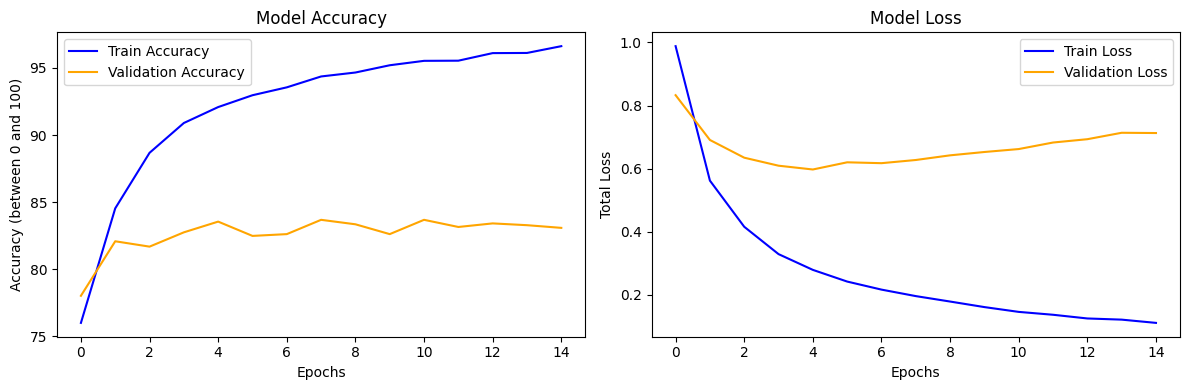

In [33]:
import matplotlib.pyplot as plt

model.eval()

test_loss = 0.0
correct_test = 0
total_test = 0

with torch.no_grad():
  for inputs, labels in test_loader:

    outputs = model(inputs)
    loss = criterion(outputs, labels)

    test_loss += loss.item() * inputs.size(0)
    _, predicted = torch.max(outputs.data, 1)
    total_test += labels.size(0)
    correct_test += (predicted == labels).sum().item()

test_loss += test_loss / len(test_loader.dataset)
test_acc = 100 * correct_test / total_test

print("---Final Test Accuracy---")
print(f"Accuracy: {test_acc:.2f}")

plt.figure(figsize=(12, 4))


plt.subplot(1, 2, 1)
plt.plot(history['train_acc'], label='Train Accuracy', color='blue')
plt.plot(history['val_acc'], label='Validation Accuracy', color='orange')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (between 0 and 100)')
plt.legend()


plt.subplot(1, 2, 2)
plt.plot(history['train_loss'], label='Train Loss', color='blue')
plt.plot(history['val_loss'], label='Validation Loss', color='orange')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Total Loss')
plt.legend()

plt.tight_layout()
plt.show()

<h1>Testing with my own letter</h1>

In [34]:
torch.save(model.state_dict(), 'ticket_classifier_model.pth')
print("Model saved successfully!")

def predict_message(message):
    model.eval()

    cleaned_msg = message.lower()
    vec_text = vectorizer.transform([cleaned_msg]).toarray()
    tensor_text = torch.tensor(vec_text, dtype=torch.float32)

    with torch.no_grad():
        output = model(tensor_text)
        _, predicted_class = torch.max(output.data, 1)

    return predicted_class.item()

my_message = "I lost my credit card yesterday, please block it immediately!"
predicted_id = predict_message(my_message)

print(f"My message: '{my_message}'")
print(f"Answer by model (Class ID): {predicted_id}")

Model saved successfully!
My message: 'I lost my credit card yesterday, please block it immediately!'
Answer by model (Class ID): 42
